# 05 - Skema Walk-Forward, Blok Validasi Internal, dan Purge

Notebook ini menggabungkan data label, fitur K1/K2, dan fitur makro K3 ke dalam satu dataset **sampel bersama**, lalu membagi rentang waktu menjadi 7 periode uji dan masing-masing 3 blok validasi internal (6 bulanan) dengan aturan *purge*.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = "../data/interim/phase4-p0"
BULAN_VALIDASI = 18
BULAN_PER_BLOK = 6

PERIODE_UJI = [
    ("2023-H1", "2023-01-01T00:00:00Z", "2023-07-01T00:00:00Z"),
    ("2023-H2", "2023-07-01T00:00:00Z", "2024-01-01T00:00:00Z"),
    ("2024-H1", "2024-01-01T00:00:00Z", "2024-07-01T00:00:00Z"),
    ("2024-H2", "2024-07-01T00:00:00Z", "2025-01-01T00:00:00Z"),
    ("2025-H1", "2025-01-01T00:00:00Z", "2025-07-01T00:00:00Z"),
    ("2025-H2", "2025-07-01T00:00:00Z", "2026-01-01T00:00:00Z"),
    ("2026-Jan-Jul", "2026-01-01T00:00:00Z", "2026-08-01T00:00:00Z"),
]

## 1. Gabungkan Dataset dan Terapkan Sampel Bersama

In [2]:
label = pd.read_parquet(f"{DATA_DIR}/02_label.parquet")
fitur = pd.read_parquet(f"{DATA_DIR}/03_fitur.parquet").drop(columns=["sigma_24"])
makro = pd.read_parquet(f"{DATA_DIR}/04_fitur_makro.parquet")

df = label.merge(fitur, on="time").merge(makro, on="time")
df = df[df["fitur_layak"] & df["target_layak"]].reset_index(drop=True)

print("Jumlah observasi sampel bersama:", len(df))

Jumlah observasi sampel bersama: 36649


## 2. Susun Batas Periode Uji, Blok Validasi, dan Purge

Aturan *purge*: data latih hanya mengambil observasi yang `target_end_time` < waktu keputusan pertama pada blok berikutnya, sehingga tidak ada label data latih yang menyeberang masuk ke blok validasi/uji.

In [3]:
def ambil_masker_blok(data, awal, akhir):
    di_blok = (data["decision_time"] >= awal) & (data["decision_time"] < akhir) & (data["target_end_time"] < akhir)
    keputusan_pertama = data.loc[di_blok, "decision_time"].min()
    return di_blok, keputusan_pertama

baris_blok = []
jumlah_blok_val = BULAN_VALIDASI // BULAN_PER_BLOK

for nama, awal_str, akhir_str in PERIODE_UJI:
    awal, akhir = pd.Timestamp(awal_str), pd.Timestamp(akhir_str)
    mulai_val = awal - pd.DateOffset(months=BULAN_VALIDASI)

    for i in range(jumlah_blok_val):
        a = mulai_val + pd.DateOffset(months=i * BULAN_PER_BLOK)
        b = a + pd.DateOffset(months=BULAN_PER_BLOK)
        baris_blok.append({"periode": nama, "blok": f"validasi-{i + 1}", "awal": a, "akhir": b})

    baris_blok.append({"periode": nama, "blok": "uji", "awal": awal, "akhir": akhir})

blok = pd.DataFrame(baris_blok)

ringkas = []
for _, r in blok.iterrows():
    di_blok, pertama = ambil_masker_blok(df, r["awal"], r["akhir"])
    latih = df["target_end_time"] < pertama
    hitung = df.loc[latih, "label_0p5"].value_counts()

    ringkas.append({
        "keputusan_pertama": pertama,
        "n_latih": int(latih.sum()),
        "n_blok": int(di_blok.sum()),
        "dibuang_purge": int(((df["decision_time"] < r["awal"]) & (df["target_end_time"] >= pertama)).sum()),
        "latih_3_kelas": all(hitung.get(k, 0) > 0 for k in ("BUY", "HOLD", "SELL")),
    })

blok = pd.concat([blok, pd.DataFrame(ringkas)], axis=1)
blok

,periode,blok,awal,akhir,keputusan_pertama,n_latih,n_blok,dibuang_purge,latih_3_kelas
0,2023-H1,validasi-1,2021-07-01 00:00:00+00:00,2022-01-01 00:00:00+00:00,2021-07-01 02:00:00+00:00,8279,2814,0,True
1,2023-H1,validasi-2,2022-01-01 00:00:00+00:00,2022-07-01 00:00:00+00:00,2022-01-03 02:00:00+00:00,11093,2807,0,True
2,2023-H1,validasi-3,2022-07-01 00:00:00+00:00,2023-01-01 00:00:00+00:00,2022-07-01 02:00:00+00:00,13901,2851,0,True
3,2023-H1,uji,2023-01-01 00:00:00+00:00,2023-07-01 00:00:00+00:00,2023-01-03 02:00:00+00:00,16752,2807,0,True
4,2023-H2,validasi-1,2022-01-01 00:00:00+00:00,2022-07-01 00:00:00+00:00,2022-01-03 02:00:00+00:00,11093,2807,0,True
5,2023-H2,validasi-2,2022-07-01 00:00:00+00:00,2023-01-01 00:00:00+00:00,2022-07-01 02:00:00+00:00,13901,2851,0,True
6,2023-H2,validasi-3,2023-01-01 00:00:00+00:00,2023-07-01 00:00:00+00:00,2023-01-03 02:00:00+00:00,16752,2807,0,True
7,2023-H2,uji,2023-07-01 00:00:00+00:00,2024-01-01 00:00:00+00:00,2023-07-03 02:00:00+00:00,19560,2829,0,True
8,2024-H1,validasi-1,2022-07-01 00:00:00+00:00,2023-01-01 00:00:00+00:00,2022-07-01 02:00:00+00:00,13901,2851,0,True
9,2024-H1,validasi-2,2023-01-01 00:00:00+00:00,2023-07-01 00:00:00+00:00,2023-01-03 02:00:00+00:00,16752,2807,0,True


### Distribusi Kelas pada Setiap Periode Uji (Ambang 0,5)

In [4]:
uji = blok[blok["blok"] == "uji"].set_index("periode")
kelas_uji = {}

for nama, r in uji.iterrows():
    di_blok, _ = ambil_masker_blok(df, r["awal"], r["akhir"])
    kelas_uji[nama] = df.loc[di_blok, "label_0p5"].value_counts().reindex(["BUY", "HOLD", "SELL"])

tabel_kelas = pd.DataFrame(kelas_uji).T
tabel_kelas["total"] = tabel_kelas.sum(axis=1)
tabel_kelas

label_0p5,BUY,HOLD,SELL,total
2023-H1,699,1410,698,2807
2023-H2,669,1470,690,2829
2024-H1,740,1385,683,2808
2024-H2,830,1380,660,2870
2025-H1,816,1228,690,2734
2025-H2,837,1218,689,2744
2026-Jan-Jul,809,1501,791,3101


## 3. Visualisasi Skema Walk-Forward

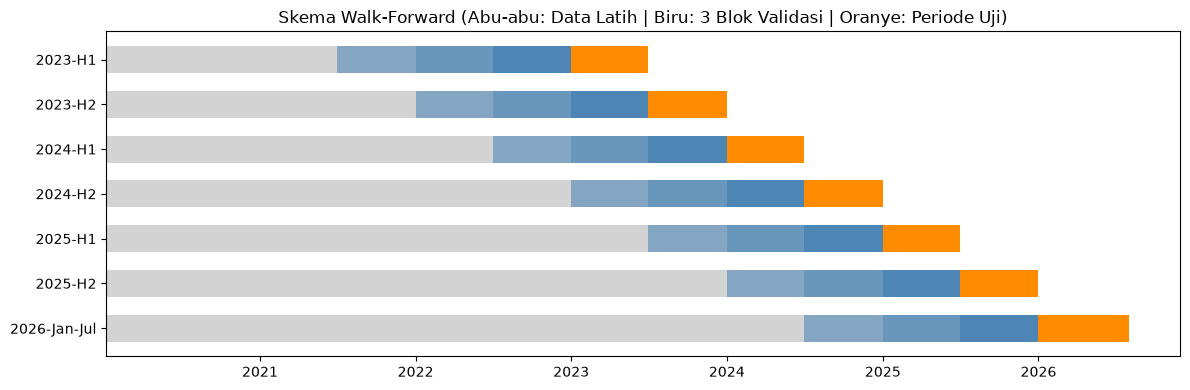

In [5]:
def gambar_batang(ax, y, a, b, color, alpha=1.0):
    a_num = mdates.date2num(a.to_pydatetime())
    b_num = mdates.date2num(b.to_pydatetime())
    ax.barh(y, b_num - a_num, left=a_num, height=0.6, color=color, alpha=alpha)

fig, ax = plt.subplots(figsize=(12, 4))
awal_data = df["decision_time"].min()

for i, (nama, g) in enumerate(blok.groupby("periode", sort=False)):
    y = len(uji) - i
    r_uji = g[g["blok"] == "uji"].iloc[0]
    gambar_batang(ax, y, awal_data, r_uji["awal"], color="lightgray")

    for _, r in g[g["blok"] != "uji"].iterrows():
        nomor_val = int(r["blok"][-1])
        gambar_batang(ax, y, r["awal"], r["akhir"], color="steelblue", alpha=0.35 + 0.2 * nomor_val)

    gambar_batang(ax, y, r_uji["awal"], r_uji["akhir"], color="darkorange")

ax.xaxis_date()
ax.set_yticks(range(len(uji), 0, -1), uji.index)
ax.set_title("Skema Walk-Forward (Abu-abu: Data Latih | Biru: 3 Blok Validasi | Oranye: Periode Uji)")
plt.tight_layout()
plt.show()

In [6]:
df.to_parquet(f"{DATA_DIR}/05_dataset.parquet", index=False)
blok.to_csv(f"{DATA_DIR}/05_blok.csv", index=False)
print("Selesai! Tersimpan:", f"{DATA_DIR}/05_dataset.parquet", df.shape, "dan 05_blok.csv")

Selesai! Tersimpan: ../data/interim/phase4-p0/05_dataset.parquet (36649, 71) dan 05_blok.csv
